In [1]:
import glob
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import h5py
import uproot
from scipy.spatial import cKDTree
from matplotlib.patches import Circle
import os

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name, dpi=300):
    plt.savefig(
        os.path.join(FIG_DIR, f"{name}.pdf"),
        bbox_inches="tight"
    )
    plt.savefig(
        os.path.join(FIG_DIR, f"{name}.png"),
        dpi=dpi,
        bbox_inches="tight"
    )
    plt.show()
    

plt.rcParams['figure.figsize'] = (9, 9)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 18
plt.rcParams['font.size'] = 18


# ============================================================
# Normalization
# ============================================================

POT_TARGET = 5e13
POT_MC = 5e13

NORMALIZATION = 1#POT_TARGET / POT_MC



print(f"Normalization factor: {NORMALIZATION:.2e}")

def extrapolate_to_z(x, y, z, px, py, pz, z_target):
    """
    Extrapolate particle positions to z_target assuming straight-line motion.

    Returns
    -------
    x_target, y_target : np.ndarray
        x and y coordinates at z = z_target.
    """
    dz = z_target - z

    x_target = x + (px / pz) * dz
    y_target = y + (py / pz) * dz

    return x_target, y_target



# ============================================================
# Function to load one simulation file
# ============================================================

def load_simulation_file(filename, normalization=NORMALIZATION):

    print(f"Loading: {filename}")

    with open(filename, "rb") as f:
        data = pickle.load(f)
    # print(data.keys())
    weight = np.asarray(data["weight"])
    evt_n = np.asanyarray(data["evt_n"])
    pdg = np.asanyarray(data["pdg"])
    data_plane = data['planes'][2]

    x = np.asarray(data_plane["x"])
    y = np.asarray(data_plane["y"])
    try:
        z = np.asarray(data_plane["z"])
    except:
        z = np.zeros_like(x)

    px = np.asarray(data_plane["px"])
    py = np.asarray(data_plane["py"])
    pz = np.asarray(data_plane["pz"])

    x_at_30, y_at_30 = extrapolate_to_z(
        x,
        y,
        z,
        px,
        py,
        pz,
        z_target=30.6
    )


    bouncing = ((np.abs(x_at_30) > 3) | (np.abs(y_at_30) > 3))
    front = (np.abs(x_at_30) < 0.5) & (np.abs(y_at_30) < 1.35)
    # print(fr"  Weight sum no normalized  : {weight.sum():,.2e} $\pm$ {np.sqrt((weight**2).sum()):,.2e}")
    # Apply POT normalization
    weight = weight * normalization
    # print(fr"  Weight sum normalized  : {weight.sum():,.2e} $\pm$ {np.sqrt((weight**2).sum()):,.2e}")

    # ----------------------------------------------------
    # Check lengths
    # ----------------------------------------------------

    arrays = {
        "x": x,
        "y": y,
        "z": z,
        "px": px,
        "py": py,
        "pz": pz,
        "weight": weight,
        "evt_n": evt_n,
        "bouncing": bouncing,
        "front": front,
        "pdg": pdg
    }

    lengths = {key: len(value) for key, value in arrays.items()}

    if len(set(lengths.values())) != 1:
        raise ValueError(
            f"Inconsistent array lengths in {filename}: {lengths}"
        )

    return arrays


# ============================================================
# Load all simulation outputs
# ============================================================

import re

files = glob.glob("outputs/TRY6_UBT_T1_seed_*.pkl")

files = sorted(
    files,
    key=lambda f: int(re.search(r"seed_(\d+)\.pkl$", f).group(1))
)

print(f"\nFound {len(files)} files")

if len(files) == 0:
    raise RuntimeError("No files found!")

seed_numbers = [
    int(re.search(r"seed_(\d+)\.pkl$", f).group(1))
    for f in files
]

missing = sorted(
    set(range(min(seed_numbers), max(seed_numbers) + 1))
    - set(seed_numbers)
)

print(f"Found {len(files)} files")
print(f"Seed range: {min(seed_numbers)} → {max(seed_numbers)}")

if missing:
    print(f"⚠️ Missing seeds: {missing}")
else:
    print("✓ No missing seeds.")



data_planes = {
    "x": [],
    "y": [],
    "z": [],
    "px": [],
    "py": [],
    "pz": [],
    "weight": [],
    "evt_n": [],
    "bouncing": [],
    "front": [],
    "pdg": []
}


# ============================================================
# Read and combine all files
# ============================================================

for i, filename in enumerate(files):

    # print(f"[{i+1}/{len(files)}] {filename}")

    data = load_simulation_file(filename)

    for key in data:
        data_planes[key].append(data[key])


# ============================================================
# Concatenate all files
# ============================================================

for key in data_planes:

    data_planes[key] = np.concatenate(
        data_planes[key]
    )

Normalization factor: 1.00e+00

Found 10506 files
Found 10506 files
Seed range: 0 → 10505
✓ No missing seeds.
Loading: outputs/TRY6_UBT_T1_seed_0.pkl
Loading: outputs/TRY6_UBT_T1_seed_1.pkl
Loading: outputs/TRY6_UBT_T1_seed_2.pkl
Loading: outputs/TRY6_UBT_T1_seed_3.pkl
Loading: outputs/TRY6_UBT_T1_seed_4.pkl
Loading: outputs/TRY6_UBT_T1_seed_5.pkl
Loading: outputs/TRY6_UBT_T1_seed_6.pkl
Loading: outputs/TRY6_UBT_T1_seed_7.pkl
Loading: outputs/TRY6_UBT_T1_seed_8.pkl
Loading: outputs/TRY6_UBT_T1_seed_9.pkl
Loading: outputs/TRY6_UBT_T1_seed_10.pkl
Loading: outputs/TRY6_UBT_T1_seed_11.pkl
Loading: outputs/TRY6_UBT_T1_seed_12.pkl
Loading: outputs/TRY6_UBT_T1_seed_13.pkl
Loading: outputs/TRY6_UBT_T1_seed_14.pkl
Loading: outputs/TRY6_UBT_T1_seed_15.pkl
Loading: outputs/TRY6_UBT_T1_seed_16.pkl
Loading: outputs/TRY6_UBT_T1_seed_17.pkl
Loading: outputs/TRY6_UBT_T1_seed_18.pkl
Loading: outputs/TRY6_UBT_T1_seed_19.pkl
Loading: outputs/TRY6_UBT_T1_seed_20.pkl
Loading: outputs/TRY6_UBT_T1_seed_21.pk

In [2]:
check = True

TIME IS APPLIED RANDOMLY

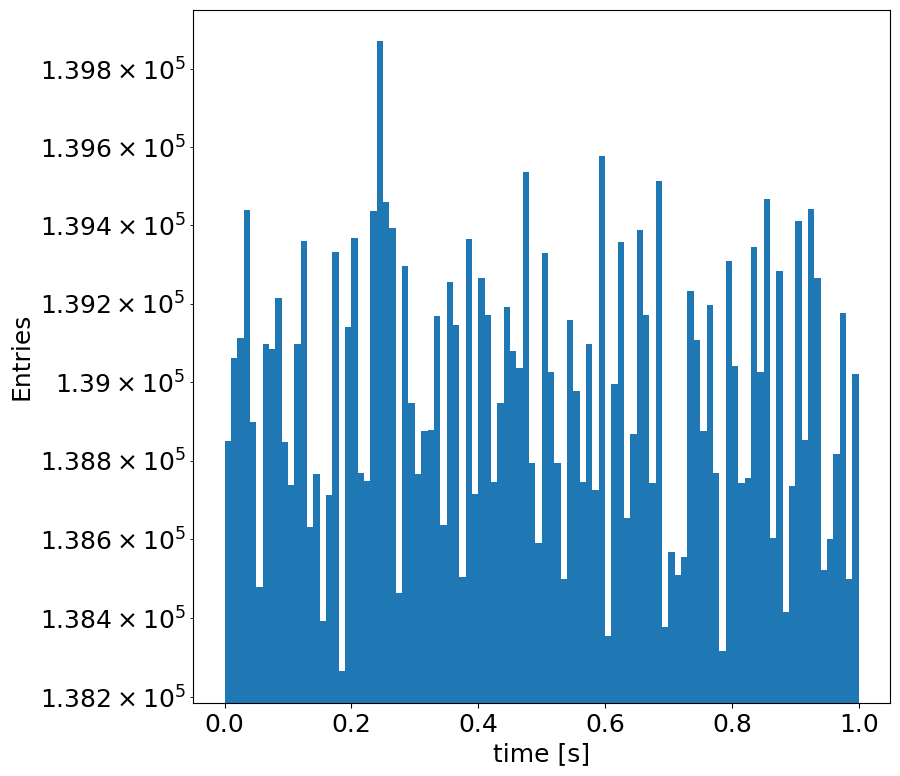

CHECK: renormalization result: new -> 3.06e+04 Hz, original -> 3.06e+04 Hz


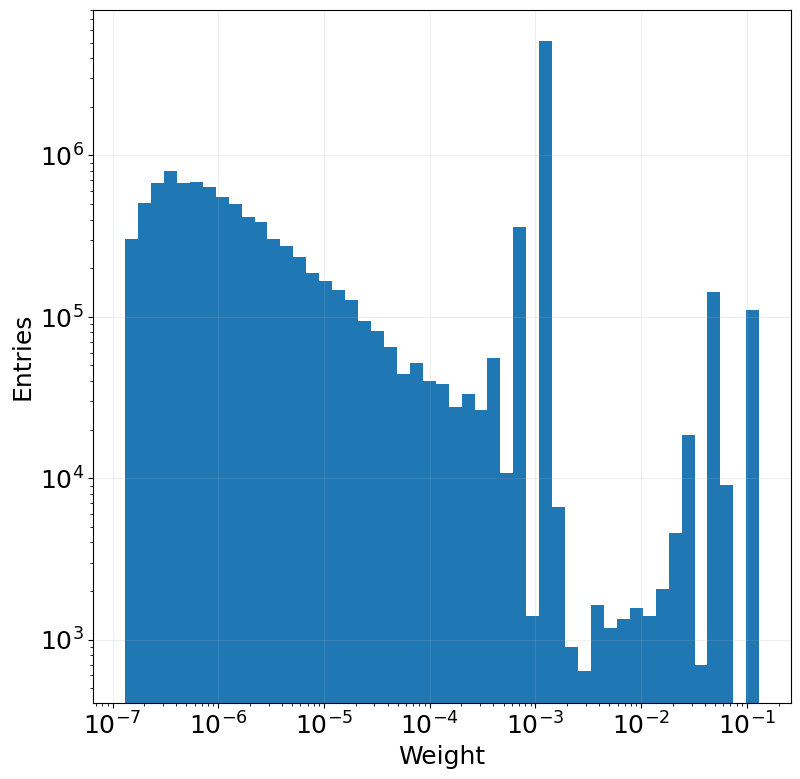

In [3]:
rng = np.random.default_rng()
# data_planes["time"] = 10 ** rng.uniform(
#     np.log10(1),       # 1 ps
#     np.log10(1e12),    # 1 s
#     len(data_planes["x"])
# ).astype(np.float64)

data_planes["time"] = rng.uniform(
    0,  
    1, 
    len(data_planes["x"])
).astype(np.float64)


if check:
    plt.hist(
        data_planes["time"],
        bins=100
    )
    plt.yscale("log")
    plt.xlabel("time [s]")
    plt.ylabel("Entries")
    save_fig("Time_distribution")
    plt.show()



order = np.argsort(data_planes["time"])
for key in data_planes:
    data_planes[key] = data_planes[key][order]


unique_evt, counts = np.unique(data_planes['evt_n'], return_counts=True)
counts_per_event = dict(zip(unique_evt, counts))
n_repeats = np.array([counts_per_event[e] for e in data_planes['evt_n']])

data_planes["weights_corrected"] = data_planes['weight'] / n_repeats
data_planes["weights_corrected"] *= data_planes['weight'].sum() / data_planes["weights_corrected"].sum()

data_planes["weights_corrected"] /= len(files)

print(f"CHECK: renormalization result: new -> {data_planes["weights_corrected"].sum():.2e} Hz, original -> {data_planes['weight'].sum()/len(files):.2e} Hz")

if check:
    bins = np.logspace(np.log10(data_planes["weights_corrected"][data_planes["weights_corrected"]>0].min()), np.log10(data_planes["weights_corrected"].max()), 50)

    plt.hist(data_planes["weights_corrected"], bins=bins)
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Weight")
    plt.ylabel("Entries")
    plt.grid(alpha=0.2)
    save_fig("weight_distribution_after_normalization")
    plt.show()


SELECTION CRITERIA:

1. MINIMUM TRACK MOMENTUM P>1 GeV/c
2. MINIMUM NUMBER OF TRACKS n>25 == 3 tracking stations
3. CHI-SQUARE X^2/nfd<5
4. HITS BEFORE AND AFTER THE SPECTROMETER (TRUE IF 2 TRUE)

Here I apply immediately the first one, this reduce the sample 

In [ ]:
p = np.sqrt( data_planes["px"]**2 + data_planes["py"]**2 + data_planes["pz"]**2 )
mask_p = p > 1 # GeV/c

if check:

    # Before / after cut
    n_total = len(mask_p)
    n_accepted = mask_p.sum()
    n_rejected = n_total - n_accepted

    accepted_pct = 100 * n_accepted / n_total
    rejected_pct = 100 * n_rejected / n_total

    print(f"Muon rejected: {rejected_pct:.2f} %")
    print(f"Muon accepted: {accepted_pct:.2f} %")

    bins = np.logspace(
        np.log10(10**-1),
        np.log10(400),
        100
    )

    # plt.figure(figsize=(8, 6))

    plt.hist(
        p[p > 0],
        bins=bins,
        cumulative=True,
        density=True,
        histtype="step",
        linewidth=2,
        label="All muons"
    )

    plt.xscale("log")

    # Momentum cut
    plt.axvline(
        x=1,
        color="red",
        linestyle="--",
        linewidth=2,
        label=r"Cut: $p > 1$ GeV/c"
    )



    # Horizontal line showing rejected percentage
    plt.axhline(
        y=rejected_pct / 100,
        color="orange",
        linestyle=":",
        linewidth=2,
        label=f"Rejected: {rejected_pct:.2f}%"
    )

    plt.xlabel(r"$|\vec{p}|$ [GeV/c]")
    plt.ylabel("Cumulative fraction [%]")

    # Convert 0–1 to 0–100%
    plt.gca().yaxis.set_major_formatter(
        lambda x, pos: f"{100*x:.0f}%"
    )



    plt.xlabel(r"$p$ [GeV/$c$]")
    plt.ylabel("Cumulative fraction")
    plt.title("Momentum selection")

    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()
    save_fig("momentum_selection")

for key in data_planes:

    data_planes[key] = data_planes[key][mask_p]

print(data_planes["weights_corrected"].sum())

Selection on the location at TIMING DETECTOR

In [ ]:
x_at_92650, y_at_92650 = extrapolate_to_z(
        data_planes['x'],
        data_planes['y'],
        data_planes['z'],
        data_planes['px'],
        data_planes['py'],
        data_planes['pz'],
        z_target=94.850-2.14
    )

mask_timing_det_loc = (np.abs(x_at_92650)<2) & (np.abs(y_at_92650)<3)

if check:

    # Before / after cut
    n_total = len(mask_timing_det_loc)
    n_accepted = mask_timing_det_loc.sum()
    n_rejected = n_total - n_accepted

    accepted_pct = 100 * n_accepted / n_total
    rejected_pct = 100 * n_rejected / n_total

    print(f"Muon rejected: {rejected_pct:.2f} %")
    print(f"Muon accepted: {accepted_pct:.2f} %")

    max_xy = np.maximum(np.abs(x_at_92650), np.abs(y_at_92650))

    bins = np.logspace(
        np.log10(10**-1),
        np.log10(4),
        100
    )

    # plt.figure(figsize=(8, 6))

    plt.hist(
        max_xy,
        bins=bins,
        cumulative=True,
        density=True,
        histtype="step",
        linewidth=2,
        label="All muons"
    )

    plt.xscale("log")

    # Momentum cut
    plt.axvline(
        x=2,
        color="red",
        linestyle="--",
        linewidth=2,
        label=r"Cut: $max_xy > 2$ GeV/c"
    )



    # Horizontal line showing rejected percentage
    plt.axhline(
        y=accepted_pct / 100,
        color="orange",
        linestyle=":",
        linewidth=2,
        label=f"Rejected: {rejected_pct:.2f}%"
    )

    plt.xlabel(r"$max(X,Y)$ [m] @z_timing = 92.65 m [GeV/c]")
    plt.ylabel("Cumulative fraction [%]")

    # Convert 0–1 to 0–100%
    plt.gca().yaxis.set_major_formatter(
        lambda x, pos: f"{100*x:.0f}%"
    )

    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()

    save_fig("timing_acceptance")
    plt.show()
    fig, ax = plt.subplots(figsize=(9, 8))
    h = ax.hist2d(
        data_planes['x'],
        data_planes['y'],
        bins=100,
        weights=data_planes['weights_corrected'],
        norm=LogNorm(),
        cmap="viridis"
    )    
    cbar = fig.colorbar(h[3], ax=ax)
    cbar.set_label("Rate [Hz]")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    
    ax.set_title(r"Muon distribution at $z=82$ m")

    save_fig("muon_xy_sst1")

    plt.show()


for key in data_planes:

    data_planes[key] = data_planes[key][mask_timing_det_loc]
len(data_planes[key]), len(data_planes[key])/12865446

In [ ]:
x_at_92650, y_at_92650 = extrapolate_to_z(
        data_planes['x'],
        data_planes['y'],
        data_planes['z'],
        data_planes['px'],
        data_planes['py'],
        data_planes['pz'],
        z_target=94.850-2.14
    )


fig, ax = plt.subplots(figsize=(9, 8))
h = ax.hist2d(
    x_at_92650,
    y_at_92650,
    bins=100,
    weights=data_planes['weights_corrected'],
    norm=LogNorm(),
    cmap="viridis"
)    
cbar = fig.colorbar(h[3], ax=ax)
cbar.set_label("Rate [Hz]")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")

ax.set_title(rf"Muon distribution at $z={94.850-2.14:.2f}$ m")

save_fig("muon_xy_timing")

plt.show()

RE-NORMALIZATION

The weight are renormalize by the number of repetition of the same index among the resulting muons

CATEGORIES

In [ ]:
print(f"The number of muons hitting SST1 that bounce on the wall is {100*data_planes['bouncing'].sum()/len(data_planes['bouncing']):.2f}%")
print(f"The number of muons hitting SST1 that come from front of the wall is {100*data_planes['front'].sum()/len(data_planes['front']):.2f}%")


if check:
    x_at_30, y_at_30 = extrapolate_to_z(
        data_planes["x"],
        data_planes["y"],
        data_planes["z"],
        data_planes["px"],
        data_planes["py"],
        data_planes["pz"],
        z_target=30.6
        )

    x_bins = np.arange(-3, 3 + 0.05, 0.05)
    y_bins = np.arange(-3, 3 + 0.05, 0.05)
    temp = ((np.abs(x_at_30)>3) | (np.abs(y_at_30)>3))
    print(f"The number of muons bouncing is {data_planes['bouncing'].sum():.2f}")
    print(f"exclude from the plot are {temp.sum()}/{len(temp)}")
    N = len(x_at_30)
    plt.hist2d(
        x_at_30,
        y_at_30,
        bins=[x_bins, y_bins],
        weights=100*data_planes['weights_corrected'] / data_planes['weights_corrected'].sum(),
        # weights=data_planes['weights_corrected'],

        norm = LogNorm()
    )

    # plt.xlim(-3, 3)
    # plt.ylim(-3, 3)
    plt.xlabel("x [m]")
    plt.ylabel("y [m]")
    plt.colorbar(label="Density count [%]")
    plt.minorticks_on()
    plt.grid(which="major", linewidth=0.8)
    plt.grid(which="minor", linewidth=0.3)

   # UBT boundaries

    # Vertical boundaries: x = ±0.5
    plt.vlines(
        x=0.5,
        ymin=-1.35,
        ymax=1.35,
        color="red",
        linestyle="--",
        linewidth=2,
        label="UBT"
    )

    plt.vlines(
        x=-0.5,
        ymin=-1.35,
        ymax=1.35,
        color="red",
        linestyle="--",
        linewidth=2,
    )

    # Horizontal boundaries: y = ±1.35
    plt.hlines(
        y=1.35,
        xmin=-0.5,
        xmax=0.5,
        color="red",
        linestyle="--",
        linewidth=2,
    )

    plt.hlines(
        y=-1.35,
        xmin=-0.5,
        xmax=0.5,
        color="red",
        linestyle="--",
        linewidth=2,
    )
    fig.suptitle("Backtracking to the decay-vessel wall")

    save_fig("backtracking_validation")

    plt.show()

CROSS OVER

In [ ]:
x_at_30, y_at_30 = extrapolate_to_z(
    data_planes["x"],
    data_planes["y"],
    data_planes["z"],
    data_planes["px"],
    data_planes["py"],
    data_planes["pz"],
    z_target=30.6
)

# True if x and pdg have opposite signs
data_planes["cross_over"] = (x_at_30 * data_planes["pdg"]) > 0

cross_over_percentage = (
    100 * data_planes["cross_over"].sum() / len(data_planes["cross_over"])
)

print(f"The cross-over percentage is: {cross_over_percentage:.3f} %")

In [ ]:
print(f"Number of surviving muons is {len(data_planes['x'])}")

DECAY VESSEL

Find the lateral interaction with SBT

In [ ]:

def backtrack_to_lateral(
    x0, y0, z0,
    px, py, pz,
    z_min=30.6,
    z_max=80.6,
    x_min=0.5,
    x_max=2.0,
    y_min=1.35,
    y_max=3.0,
):
    # Slopes of the expanding lateral walls
    ax = (x_max - x_min) / (z_max - z_min)
    ay = (y_max - y_min) / (z_max - z_min)

    # Trajectory slopes
    vx = px / pz
    vy = py / pz

    # Candidate intersections
    with np.errstate(divide="ignore", invalid="ignore"):

        # x = +X(z)
        z_xplus = (
            x_min - x0 + vx * z0 - ax * z_min
        ) / (vx - ax)

        # x = -X(z)
        z_xminus = (
            -x_min - x0 + vx * z0 + ax * z_min
        ) / (vx + ax)

        # y = +Y(z)
        z_yplus = (
            y_min - y0 + vy * z0 - ay * z_min
        ) / (vy - ay)

        # y = -Y(z)
        z_yminus = (
            -y_min - y0 + vy * z0 + ay * z_min
        ) / (vy + ay)

        # Position at front plane
        x_front ,y_front = extrapolate_to_z(x0, y0, z0, px, py, pz, z_target=z_min)

    # Front is admissible only if inside front aperture
    front_valid = (
        (np.abs(x_front) <= x_min)
        & (np.abs(y_front) <= y_min)
        & (z_min <= z0)
    )
    
    z_candidates = np.column_stack([
        z_xplus,
        z_xminus,
        z_yplus,
        z_yminus,
        np.where(front_valid, z_min, np.nan)
    ])

    # Only genuine lateral intersections:
    # strictly inside the entrance/exit z range
    valid = (
        np.isfinite(z_candidates)
        & (z_candidates >= z_min)
        & (z_candidates < z_max)
        & (z_candidates < z0[:, None])
    )
    # Backtracking: first wall encountered = largest z below z0
    z_int = np.max(
        np.where(valid, z_candidates, -np.inf),
        axis=1
    )

    # Calculate intersection coordinates
    x_int, y_int = extrapolate_to_z(
            x0,
            y0,
            z0,
            px,
            py,
            pz,
            z_target=z_int
            )

    # No lateral intersection
    no_intersection = ~np.isfinite(z_int)

    x_int[no_intersection] = np.nan
    y_int[no_intersection] = np.nan

    return z_int, x_int, y_int


z_decay_vessel, x_decay_vessel, y_decay_vessel = backtrack_to_lateral(
    data_planes["x"],
    data_planes["y"],
    data_planes["z"],
    data_planes["px"],
    data_planes["py"],
    data_planes["pz"],
)


if check:
    # --------------------------------------------------
    # Cone
    # --------------------------------------------------
    z_cone = np.linspace(30.6, 80.6, 200)

    x_cone = 0.5 + (2.0 - 0.5) * (z_cone - 30.6) / (80.6 - 30.6)
    y_cone = 1.35 + (3.0 - 1.35) * (z_cone - 30.6) / (80.6 - 30.6)

    # --------------------------------------------------
    # Valid intersections
    # --------------------------------------------------
    valid = np.isfinite(z_decay_vessel)
    

    amount = 100

    x = data_planes["x"][valid][:amount]
    y = data_planes["y"][valid][:amount]
    z = data_planes["z"][valid][:amount]

    px = data_planes["px"][valid][:amount]
    py = data_planes["py"][valid][:amount]
    pz = data_planes["pz"][valid][:amount]

    xl = x_decay_vessel[valid][:amount]
    yl = y_decay_vessel[valid][:amount]
    zl = z_decay_vessel[valid][:amount]

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------
    fig, (ax_x, ax_y) = plt.subplots(
    1, 2, figsize=(14, 7), sharey=False
    )

    # --------------------------------------------------
    # X-Z cone: z horizontal, x vertical
    # --------------------------------------------------
    ax_x.plot(z_cone, x_cone, "b--", lw=2, label="He Balloon")
    ax_x.plot(z_cone, -x_cone, "b--", lw=2)
    ax_x.fill_between(z_cone, -x_cone, x_cone, alpha=0.15)

    # --------------------------------------------------
    # SST1: z = 82
    # --------------------------------------------------
    ax_x.vlines(x=82, ymin=-2, ymax=2, color="r", linestyle="--", lw=1,  label="SST1")

    # --------------------------------------------------
    # Y-Z cone: z horizontal, y vertical
    # --------------------------------------------------
    ax_y.plot(z_cone, y_cone, "b--", lw=2, label="He Balloon")
    ax_y.plot(z_cone, -y_cone, "b--", lw=2)
    ax_y.fill_between(z_cone, -y_cone, y_cone, alpha=0.15)

    # --------------------------------------------------
    # SST1: z = 82
    # --------------------------------------------------
    ax_y.vlines(x=82, ymin=-3, ymax=3, color="r", linestyle="--", lw=1,  label="SST1")

    # --------------------------------------------------
    # Backtracked tracks
    # --------------------------------------------------
    for xi, yi, zi, pxi, pyi, pzi, xl_i, yl_i, zl_i in zip(
        x, y, z, px, py, pz, xl, yl, zl
    ):
        # Track parameter to lateral intersection
        t = (zl_i - zi) / pzi

        x_check = xi + t * pxi
        y_check = yi + t * pyi

        # --------------------------------------------------
        # X-Z
        # --------------------------------------------------
        ax_x.plot(
            [zi, zl_i],
            [xi, x_check],
            "-",
            alpha=0.5
        )

        ax_x.plot(
            zi, xi,
            "o",
            ms=3
        )

        ax_x.plot(
            zl_i, xl_i,
            "x",
            ms=7,
            mew=2
        )

        # --------------------------------------------------
        # Y-Z
        # --------------------------------------------------
        ax_y.plot(
            [zi, zl_i],
            [yi, y_check],
            "-",
            alpha=0.5
        )

        ax_y.plot(
            zi, yi,
            "o",
            ms=3
        )

        ax_y.plot(
            zl_i, yl_i,
            "x",
            ms=7,
            mew=2
        )

    # --------------------------------------------------
    # Formatting
    # --------------------------------------------------
    ax_x.set(
        xlabel="z",
        ylabel="x",
        title="Backtracking validation — X-Z",
        xlim=(25, 85),
        ylim=(-2.5, 2.5)
    )

    ax_y.set(
        xlabel="z",
        ylabel="y",
        title="Backtracking validation — Y-Z",
        xlim=(28, 85),
        ylim=(-4, 4)
    )

    ax_x.grid(alpha=0.2)
    ax_y.grid(alpha=0.2)

    ax_x.legend()
    ax_y.legend()
    save_fig("Decay_vessel_backtracking")
    plt.tight_layout()
    plt.show()

In [ ]:
save_files = False

In [ ]:
import numpy as np


def make_vessel_dataset(data_selected):
    """
    Build a compact dataset containing the information needed
    for detector-veto optimization.
    """
    x_at_30, y_at_30 = extrapolate_to_z( data_selected["x"], data_selected["y"], data_selected["z"], data_selected["px"], data_selected["py"], data_selected["pz"], z_target=30.6)

    z_vessel, x_vessel, y_vessel = backtrack_to_lateral(
        data_selected["x"],
        data_selected["y"],
        data_selected["z"],
        data_selected["px"],
        data_selected["py"],
        data_selected["pz"],
    )


    # --------------------------------------------------------
    # Categories
    # --------------------------------------------------------

    bouncing = ((np.abs(x_at_30) > 3) | (y_at_30 < -3.36))
    front = (np.abs(x_at_30) < 0.5) & (np.abs(y_at_30) < 1.35)
    cross_over = (x_at_30 * data_selected["pdg"]) > 0

    dataset = {
        "x": data_selected["x"],
        "y": data_selected["y"],
        "z": data_selected["z"],

        "px": data_selected["px"],
        "py": data_selected["py"],
        "pz": data_selected["pz"],

        "weight": data_selected["weight"],

        "x_ubt": x_at_30,
        "y_ubt": y_at_30,

        "bouncing": bouncing,
        "front": front,
        "cross_over": cross_over,

        "x_vessel": x_vessel,
        "y_vessel": y_vessel,
        "z_vessel": z_vessel,
    }

    return dataset

if save_files:
    vessel_dataset = make_vessel_dataset(data_planes)

    np.savez_compressed(
        "muon_vessel_dataset.npz",
        **vessel_dataset
    )

TIME BUNCHING

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def find_time_pairs(data_planes, half_window=200e-12):

    time = data_planes["time"]

    left = np.searchsorted(
        time,
        time - half_window,
        side="left"
    )

    right = np.searchsorted(
        time,
        time + half_window,
        side="right"
    )

    # Number of other tracks within the time window
    n_in_window = right - left - 1

    pairs = []

    for i in range(len(time)):

        j = np.arange(
            max(i + 1, left[i]),
            right[i]
        )

        if len(j) > 0:
            pairs.append(
                np.column_stack([
                    np.full(len(j), i, dtype=int),
                    j
                ])
            )

    if pairs:
        pairs = np.vstack(pairs)
    else:
        pairs = np.empty((0, 2), dtype=int)

    return pairs, n_in_window


time_pairs, n_in_window = find_time_pairs(data_planes)

print("Number of tracks:", len(data_planes["time"]))
print("Time-compatible pairs:", len(time_pairs))


# Plot
plt.figure(figsize=(8, 5))

plt.hist(
    n_in_window,
    bins=20,
    histtype="step",
    linewidth=2
)

plt.xlabel("Number of points within ±200 ps")
plt.ylabel("Entries")
plt.title("Number of time-compatible points per event")
plt.grid(alpha=0.2)
plt.yscale("log")
plt.ylim(1, 10**7)
save_fig("time_pairs")
plt.show()

TRACK PAIRS SELECTION CRITERIA

Track Pairs Selection Criteria

DOCA: The distance of closest approach is the minimum distance between two lines

To evaluate it:

1. Take two points and their respective directions in SST1
2. Evaluate the minumum distance d
3. If the distance is d < 2 cm, then retrieve the vertex
4. if the vertex is within the decay vessel region, then extrapolate the point at the target z = -2.14 m
5. if the IP is lower than 2.5 m the vertex is a candidate

In [ ]:
def calculate_doca(data_planes, time_pairs, opposite_charge=True):

    r = np.column_stack([
        data_planes["x"],
        data_planes["y"],
        data_planes["z"]
    ])

    p = np.column_stack([
        data_planes["px"],
        data_planes["py"],
        data_planes["pz"]
    ])

    i = time_pairs[:, 0]
    j = time_pairs[:, 1]

    r1 = r[i]
    r2 = r[j]

    p1 = p[i]
    p2 = p[j]

    # --------------------------------------------------
    # Charge selection
    # --------------------------------------------------

    if opposite_charge:
        pdg1 = data_planes["pdg"][i]
        pdg2 = data_planes["pdg"][j]

        charge_mask = pdg1 * pdg2 < 0
    else:
        charge_mask = np.ones(len(time_pairs), dtype=bool)

    # --------------------------------------------------
    # DOCA
    # --------------------------------------------------

    dr = r1 - r2

    cross = np.cross(p1, p2)
    cross_norm = np.linalg.norm(cross, axis=1)

    valid = charge_mask & (cross_norm > 1e-12)

    doca = np.full(len(time_pairs), np.inf)

    doca[valid] = (
        np.abs(np.sum(dr[valid] * cross[valid], axis=1))
        / cross_norm[valid]
    )

    # --------------------------------------------------
    # Closest points
    # --------------------------------------------------

    w = r1 - r2

    a = np.sum(p1 * p1, axis=1)
    b = np.sum(p1 * p2, axis=1)
    c = np.sum(p2 * p2, axis=1)

    d = np.sum(p1 * w, axis=1)
    e = np.sum(p2 * w, axis=1)

    den = a * c - b * b

    valid &= np.abs(den) > 1e-12

    s = np.zeros(len(time_pairs))
    u = np.zeros(len(time_pairs))

    s[valid] = (
        b[valid] * e[valid]
        - c[valid] * d[valid]
    ) / den[valid]

    u[valid] = (
        a[valid] * e[valid]
        - b[valid] * d[valid]
    ) / den[valid]

    point1 = r1 + s[:, None] * p1
    point2 = r2 + u[:, None] * p2

    # --------------------------------------------------
    # Vertex
    # --------------------------------------------------

    vertex = 0.5 * (point1 + point2)

    # --------------------------------------------------
    # Vertex momentum = sum of the two momenta
    # --------------------------------------------------

    momentum = p1 + p2

    return doca, vertex, momentum


doca, vertex, momentum = calculate_doca(data_planes, time_pairs,opposite_charge=False)

print("Number of pairs:", len(time_pairs))
print("Number of valid DOCA:", np.sum(np.isfinite(doca)))
print("Minimum DOCA:", np.nanmin(doca))
print("Maximum DOCA:", np.nanmax(doca))

mask_doca_2cm = doca < 0.02

selected_doca = doca[mask_doca_2cm]
selected_vertex = vertex[mask_doca_2cm]
selected_momentum = momentum[mask_doca_2cm]
selected_pairs = time_pairs[mask_doca_2cm]


print("Pairs with DOCA < 2 cm:", len(selected_pairs))


if check:
    doca_finite = doca[np.isfinite(doca)]

    # Convert to cm
    doca_cm = 100 * doca_finite

    # ==========================================================
    # 1. Cumulative distribution
    # ==========================================================

    doca_sorted = np.sort(doca_cm)
    cdf = np.arange(1, len(doca_sorted) + 1) / len(doca_sorted)

    plt.figure(figsize=(8, 5))

    plt.plot(doca_sorted, cdf, lw=2)

    plt.axvline(2.0, color="r", linestyle="--", label="2 cm")

    # Fraction below 2 cm
    fraction_2cm = np.mean(doca_cm <= 2.0)

    plt.axhline(
        fraction_2cm,
        color="r",
        linestyle=":",
        alpha=0.7
    )

    plt.xlabel("DOCA [cm]")
    plt.ylabel("Cumulative fraction")
    plt.title("Cumulative DOCA distribution")
    plt.xlim(0, 20)
    
    plt.grid(alpha=0.2)
    plt.legend()
    save_fig("doca_cumulative") 
    plt.show()

    print(f"Pairs with DOCA < 2 cm: {fraction_2cm*100:.2f}%")

    # ==========================================================
    # 2. Focused histogram around 2 cm
    # ==========================================================

    plt.figure(figsize=(8, 5))

    plt.hist(
        doca_cm,
        bins=np.linspace(0, 5, 101),  # 0 to 5 cm
        histtype="step",
        linewidth=2
    )

    plt.axvline(
        2.0,
        color="r",
        linestyle="--",
        linewidth=2,
        label="2 cm"
    )

    plt.xlabel("DOCA [cm]")
    plt.ylabel("Entries")
    plt.title("DOCA distribution — focused region")
    plt.yscale("log")
    plt.xlim(0, 5)
    plt.grid(alpha=0.2)
    plt.legend()
    save_fig("doca_histogram")
    plt.show()


    # --------------------------------------------------
    # Cone
    # --------------------------------------------------
    z_cone = np.linspace(30.6, 80.6, 200)

    x_cone = 0.5 + (2.0 - 0.5) * (z_cone - 30.6) / (80.6 - 30.6)
    y_cone = 1.35 + (3.0 - 1.35) * (z_cone - 30.6) / (80.6 - 30.6)

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------
    fig, (ax_x, ax_y) = plt.subplots(
    1, 2, figsize=(14, 7), sharey=False
    )

    # --------------------------------------------------
    # X-Z cone: z horizontal, x vertical
    # --------------------------------------------------
    ax_x.plot(z_cone, x_cone, "b--", lw=2, label="He Balloon")
    ax_x.plot(z_cone, -x_cone, "b--", lw=2)
    ax_x.fill_between(z_cone, -x_cone, x_cone, alpha=0.15)

    # --------------------------------------------------
    # SST1: z = 82
    # --------------------------------------------------
    ax_x.vlines(x=82, ymin=-2, ymax=2, color="r", linestyle="--", lw=1,  label="SST1")

    # --------------------------------------------------
    # Y-Z cone: z horizontal, y vertical
    # --------------------------------------------------
    ax_y.plot(z_cone, y_cone, "b--", lw=2, label="He Balloon")
    ax_y.plot(z_cone, -y_cone, "b--", lw=2)
    ax_y.fill_between(z_cone, -y_cone, y_cone, alpha=0.15)

    # --------------------------------------------------
    # SST1: z = 82
    # --------------------------------------------------
    ax_y.vlines(x=82, ymin=-3, ymax=3, color="r", linestyle="--", lw=1,  label="SST1")

    mask = ((np.abs(vertex[:,0])<6) & (np.abs(vertex[:,1])<6) & (vertex[:,2]<80.6) & (vertex[:,2]>30.6))

    count = 0
    for pair_idx, (i, j) in enumerate(time_pairs):

        if not mask[pair_idx]:
            continue

        x, y, z = vertex[pair_idx]

        pdg_product = 100*doca[pair_idx]#data_planes["pdg"][i] * data_planes["pdg"][j]

        ax_x.scatter(z, x)
        ax_y.scatter(z, y)

        # # Write PDG1 * PDG2 above the point
        # ax_x.annotate(
        #     f"{pdg_product:.0f}",
        #     (z, x),
        #     xytext=(0, 5),
        #     textcoords="offset points",
        #     ha="center",
        #     fontsize=8
        # )

        # ax_y.annotate(
        #     f"{pdg_product:.0f}",
        #     (z, y),
        #     xytext=(0, 5),
        #     textcoords="offset points",
        #     ha="center",
        #     fontsize=8
        # )

        count += 1

        if count > 100:
            break

    print(f"Total vertex {len(vertex)}")
    print(f"represented {count} vertex")
    print(f"Vertex inside the limit of [(-6,6),(-6,6),(30,100)]: {mask.sum()} vertex")
    print(f"Vertex outside the limit: {len(vertex) - mask.sum()} vertex")






In [ ]:
def plot_selected_vertices_and_tracks(
    data_planes,
    selected_pairs,
    selected_vertex,
    amount=100
):

    x = data_planes["x"]
    y = data_planes["y"]
    z = data_planes["z"]

    px = data_planes["px"]
    py = data_planes["py"]
    pz = data_planes["pz"]

    # --------------------------------------------------
    # Cone
    # --------------------------------------------------

    z_cone = np.linspace(30.6, 80.6, 200)

    x_cone = (
        0.5
        + (2.0 - 0.5)
        * (z_cone - 30.6)
        / (80.6 - 30.6)
    )

    y_cone = (
        1.35
        + (3.0 - 1.35)
        * (z_cone - 30.6)
        / (80.6 - 30.6)
    )

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    fig, (ax_x, ax_y) = plt.subplots(
        1, 2,
        figsize=(14, 7)
    )

    # --------------------------------------------------
    # X-Z cone
    # --------------------------------------------------

    ax_x.plot(
        z_cone,
        x_cone,
        "b--",
        lw=2,
        label="He Balloon"
    )

    ax_x.plot(
        z_cone,
        -x_cone,
        "b--",
        lw=2
    )

    ax_x.fill_between(
        z_cone,
        -x_cone,
        x_cone,
        alpha=0.15
    )

    # --------------------------------------------------
    # Y-Z cone
    # --------------------------------------------------

    ax_y.plot(
        z_cone,
        y_cone,
        "b--",
        lw=2,
        label="He Balloon"
    )

    ax_y.plot(
        z_cone,
        -y_cone,
        "b--",
        lw=2
    )

    ax_y.fill_between(
        z_cone,
        -y_cone,
        y_cone,
        alpha=0.15
    )

    # --------------------------------------------------
    # SST1
    # --------------------------------------------------

    ax_x.vlines(
        82,
        -2,
        2,
        color="r",
        linestyle="--",
        lw=1,
        label="SST1"
    )

    ax_y.vlines(
        82,
        -3,
        3,
        color="r",
        linestyle="--",
        lw=1,
        label="SST1"
    )

    # --------------------------------------------------
    # Selected pairs
    # --------------------------------------------------

    amount = min(amount, len(selected_pairs))

    for k in range(amount):

        i, j = selected_pairs[k]

        vx, vy, vz = selected_vertex[k]

        # Same color for both tracks + vertex
        color = f"C{k % 10}"

        # ==================================================
        # Track 1
        # ==================================================

        z_start = z[i]

        # Extend from original point all the way to z=-2.14
        z_line = np.linspace(
            z_start,
            30,
            100
        )

        x_line = (
            x[i]
            + (z_line - z_start) * px[i] / pz[i]
        )

        y_line = (
            y[i]
            + (z_line - z_start) * py[i] / pz[i]
        )

        ax_x.plot(
            z_line,
            x_line,
            color=color,
            alpha=0.7
        )

        ax_y.plot(
            z_line,
            y_line,
            color=color,
            alpha=0.7
        )

        # ==================================================
        # Track 2
        # ==================================================

        z_start = z[j]

        z_line = np.linspace(
            z_start,
            30,
            100
        )

        x_line = (
            x[j]
            + (z_line - z_start) * px[j] / pz[j]
        )

        y_line = (
            y[j]
            + (z_line - z_start) * py[j] / pz[j]
        )

        ax_x.plot(
            z_line,
            x_line,
            color=color,
            alpha=0.7
        )

        ax_y.plot(
            z_line,
            y_line,
            color=color,
            alpha=0.7
        )

        # ==================================================
        # Vertex
        # ==================================================

        ax_x.scatter(
            vz,
            vx,
            color=color,
            s=40,
            zorder=5
        )

        ax_y.scatter(
            vz,
            vy,
            color=color,
            s=40,
            zorder=5
        )



    # --------------------------------------------------
    # Labels
    # --------------------------------------------------

    ax_x.set_xlabel("z")
    ax_x.set_ylabel("x")
    ax_x.set_title("X-Z: selected tracks and vertices")
    ax_x.grid(alpha=0.2)
    ax_x.legend()

    ax_y.set_xlabel("z")
    ax_y.set_ylabel("y")
    ax_y.set_title("Y-Z: selected tracks and vertices")
    ax_y.grid(alpha=0.2)
    ax_y.legend()

    plt.tight_layout()
    plt.show()




In [ ]:
def select_vertices_in_cone(vertex):

    z = vertex[:, 2]


    # Cone limits
    z_min = 30.6
    z_max = 80.6
    x_min = 0.5 + (2.0 - 0.5) * (z - z_min) / (z_max - z_min)
    y_min = 1.35 + (3.0 - 1.35) * (z - z_min) / (z_max - z_min)
    keep = (
        (z >= z_min) &
        (z <= z_max) &
        (np.abs(vertex[:, 0]) <= x_min) &
        (np.abs(vertex[:, 1]) <= y_min)
    )

    return keep


mask_within_decay_vessel = select_vertices_in_cone(selected_vertex)

selected_doca = selected_doca[mask_within_decay_vessel]
selected_vertex = selected_vertex[mask_within_decay_vessel]
selected_momentum = selected_momentum[mask_within_decay_vessel]
selected_pairs = selected_pairs[mask_within_decay_vessel]

if check:

    plot_selected_vertices_and_tracks(
    data_planes,
    selected_pairs[:],
    selected_vertex[:],
    amount=100
)
    save_fig("selected_vertices")

In [ ]:
def require_info(data_planes, inx, z=None):
    print(f"\n{'='*60}")
    print(f"Information for index {inx}")
    print(f"{'='*60}")

    # Print all stored quantities
    for key, values in data_planes.items():
        value = values[inx]

        # Format numbers nicely
        if isinstance(value, (float, np.floating)):
            print(f"{key:20s}: {value:.4f}")
        else:
            print(f"{key:20s}: {value}")

    # Optional extrapolation
    if z is not None:
        x, y = extrapolate_to_z(
            data_planes["x"][inx],
            data_planes["y"][inx],
            data_planes["z"][inx],
            data_planes["px"][inx],
            data_planes["py"][inx],
            data_planes["pz"][inx],
            z
        )

        print(f"\nExtrapolation:")
        print(f"Point extrapolated @ z={z:.2f} m -> [x,y] = [{x:.4f}, {y:.4f}]")

    print(f"{'='*60}")

for pairs in selected_pairs:
    require_info(data_planes,pairs[0],30)
    require_info(data_planes,pairs[1],30)
    plt.scatter(data_planes['x'][pairs[0]],data_planes['y'][pairs[0]])
    plt.scatter(data_planes['x'][pairs[1]],data_planes['y'][pairs[1]])
plt.show()


In [ ]:
data_planes[519871]

In [ ]:
x_vertex_at_target, y_vertex_at_target = extrapolate_to_z(selected_vertex[:,0],selected_vertex[:,1],selected_vertex[:,2], selected_momentum[:,0],selected_momentum[:,1],selected_momentum[:,2], -2.14)

mask_ip = np.sqrt(x_vertex_at_target**2 + y_vertex_at_target**2) < 2.5

selected_doca = selected_doca[mask_ip]
selected_vertex = selected_vertex[mask_ip]
selected_momentum = selected_momentum[mask_ip]
selected_pairs = selected_pairs[mask_ip]
selected_pair_weight = np.prod(data_planes["weights_corrected"][selected_pairs], axis=1)

NORMALIZATION_15 = (6*10**(20))/(5*10**(13))
print(f"Normalization factor in 15 years expected PoT $6x10^{20}$, in one spill $5x10^{13}$: {NORMALIZATION_15:.1e}")

print()
print(f"The rate of each pair is: {selected_pair_weight}")
print(f"Multiplied by pairs and sum it up is {selected_pair_weight.sum():.2e}")
print(f"Renormalized for the expected PoT over 15 years: {NORMALIZATION_15*selected_pair_weight.sum():.2e}")
if check:

    fig, ax = plt.subplots()

    ax.plot(
        x_vertex_at_target,
        y_vertex_at_target,
        'x',
        label = r'@$z_{target}$'
    )

    circle = Circle(
        (0, 0),
        radius=2.5,
        fill=False,
        linestyle="--",
        linewidth=2,
        label = 'IP cut'
    )

    ax.add_patch(circle)

    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.grid(alpha=0.2)
    plt.legend()
    save_fig("ip_selection")
    plt.show()


Loading: muon_distribution_3d.pkl

========== MUON DISTRIBUTION ==========
Histogram shape: (90, 66, 101)
x range: -4.5 -> 4.499999999999968
y range: -3.3 -> 3.300000000000006
z range: 30.6 -> 81.1
Total weight: 200885685369.67468


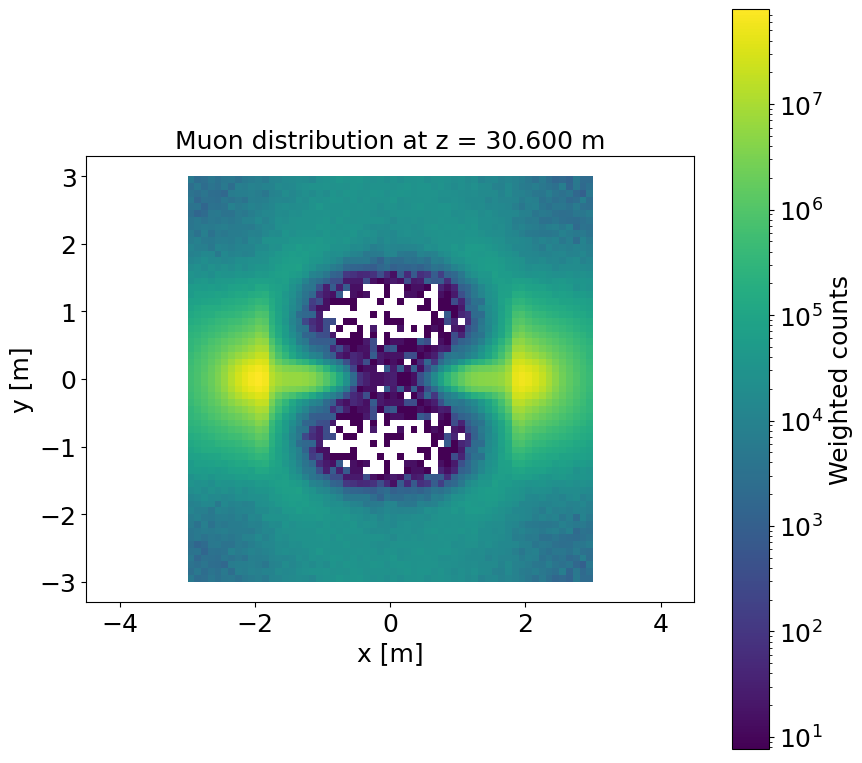

Requested z = 30.600 m, using z bin center = 30.850 m


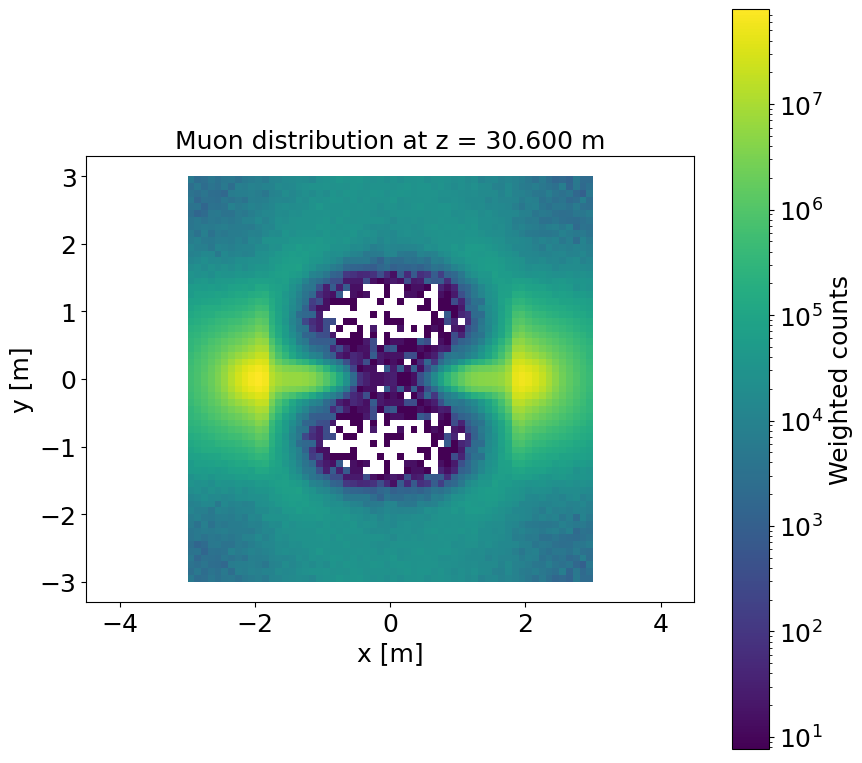

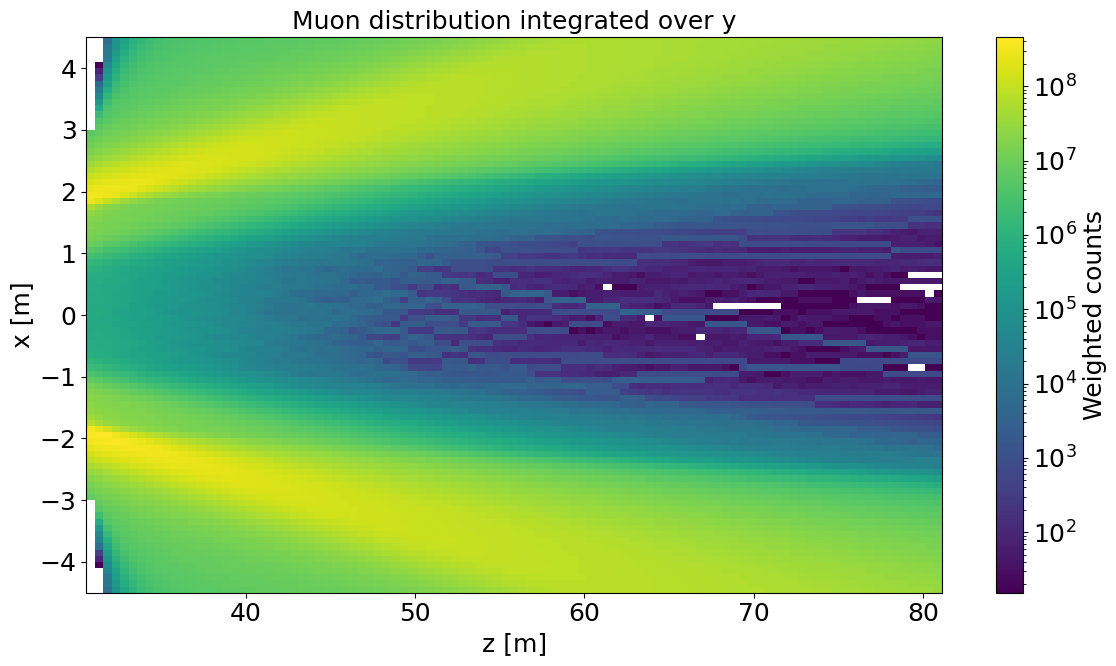

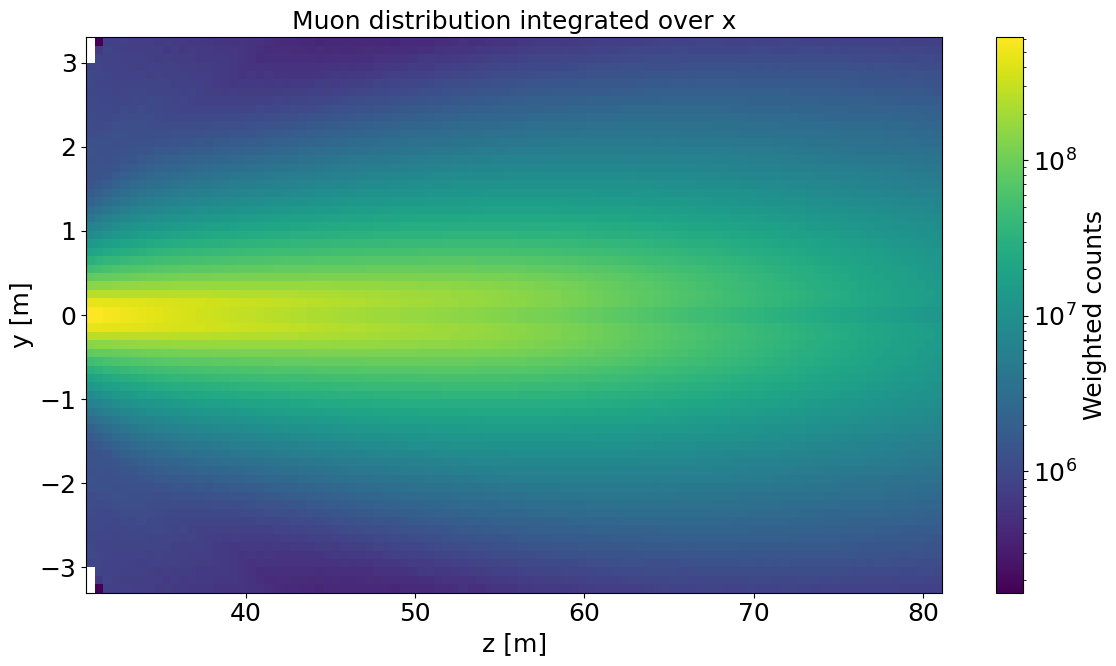

In [4]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


def load_muon_distribution(filename="muon_distribution_3d.pkl"):
    """
    Load the 3D muon distribution saved by the simulation.

    Returns
    -------
    distribution : dict
        Contains:
        H        : 3D weighted histogram [x, y, z]
        x_edges  : x bin edges
        y_edges  : y bin edges
        z_edges  : z bin edges
        dx, dy, dz : bin sizes
    """
    print(f"Loading: {filename}")

    with open(filename, "rb") as f:
        distribution = pickle.load(f)

    required = ["H", "x_edges", "y_edges", "z_edges"]

    missing = [key for key in required if key not in distribution]
    if missing:
        raise ValueError(f"Missing keys in file: {missing}")

    H = distribution["H"]

    print("\n========== MUON DISTRIBUTION ==========")
    print("Histogram shape:", H.shape)
    print("x range:", distribution["x_edges"][0], "->",
          distribution["x_edges"][-1])
    print("y range:", distribution["y_edges"][0], "->",
          distribution["y_edges"][-1])
    print("z range:", distribution["z_edges"][0], "->",
          distribution["z_edges"][-1])
    print("Total weight:", H.sum())

    return distribution


def plot_xy(distribution, iz=0, log=True):
    """
    Plot the x-y distribution at one z bin.

    Parameters
    ----------
    iz : int
        Index of the z bin.
    log : bool
        Use logarithmic color scale.
    """
    H = distribution["H"]
    x_edges = distribution["x_edges"]
    y_edges = distribution["y_edges"]
    z_edges = distribution["z_edges"]

    if iz < 0 or iz >= H.shape[2]:
        raise IndexError(f"iz must be between 0 and {H.shape[2]-1}")

    values = H[:, :, iz].T

    fig, ax = plt.subplots(figsize=(9, 8))

    if log:
        positive = values[values > 0]

        if len(positive) == 0:
            raise ValueError("This z plane contains no positive entries.")

        mesh = ax.pcolormesh(
            x_edges,
            y_edges,
            values,
            shading="auto",
            norm=LogNorm(
                vmin=positive.min(),
                vmax=positive.max()
            )
        )
    else:
        mesh = ax.pcolormesh(
            x_edges,
            y_edges,
            values,
            shading="auto"
        )

    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(f"Muon distribution at z = {z_edges[iz]:.3f} m")
    ax.set_aspect("equal")

    fig.colorbar(mesh, ax=ax, label="Weighted counts")

    plt.tight_layout()
    plt.show()


def plot_all_z(distribution, log=True):
    """
    Plot every z plane.
    """
    H = distribution["H"]

    for iz in range(H.shape[2]):
        plot_xy(distribution, iz=iz, log=log)


def get_z_slice(distribution, z):
    """
    Return the histogram slice closest to the requested z position.

    Returns
    -------
    values : 2D ndarray
    z_center : float
    iz : int
    """
    z_edges = distribution["z_edges"]
    H = distribution["H"]

    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
    iz = np.argmin(np.abs(z_centers - z))

    return H[:, :, iz], z_centers[iz], iz


def plot_at_z(distribution, z, log=True):
    """
    Plot the x-y muon distribution closest to a physical z position.

    Example:
        plot_at_z(distribution, 30.6)
    """
    _, z_center, iz = get_z_slice(distribution, z)

    print(
        f"Requested z = {z:.3f} m, "
        f"using z bin center = {z_center:.3f} m"
    )

    plot_xy(distribution, iz=iz, log=log)


def plot_xz(distribution, log=True):
    """
    Plot the x-z distribution, integrated over y.
    """
    H = distribution["H"]
    x_edges = distribution["x_edges"]
    z_edges = distribution["z_edges"]

    values = np.sum(H, axis=1).T

    fig, ax = plt.subplots(figsize=(12, 7))

    if log:
        positive = values[values > 0]
        mesh = ax.pcolormesh(
            z_edges,
            x_edges,
            values.T,
            shading="auto",
            norm=LogNorm(
                vmin=positive.min(),
                vmax=positive.max()
            )
        )
    else:
        mesh = ax.pcolormesh(
            z_edges,
            x_edges,
            values.T,
            shading="auto"
        )

    ax.set_xlabel("z [m]")
    ax.set_ylabel("x [m]")
    ax.set_title("Muon distribution integrated over y")

    fig.colorbar(mesh, ax=ax, label="Weighted counts")

    plt.tight_layout()
    plt.show()


def plot_yz(distribution, log=True):
    """
    Plot the y-z distribution, integrated over x.
    """
    H = distribution["H"]
    y_edges = distribution["y_edges"]
    z_edges = distribution["z_edges"]

    values = np.sum(H, axis=0).T

    fig, ax = plt.subplots(figsize=(12, 7))

    if log:
        positive = values[values > 0]
        mesh = ax.pcolormesh(
            z_edges,
            y_edges,
            values.T,
            shading="auto",
            norm=LogNorm(
                vmin=positive.min(),
                vmax=positive.max()
            )
        )
    else:
        mesh = ax.pcolormesh(
            z_edges,
            y_edges,
            values.T,
            shading="auto"
        )

    ax.set_xlabel("z [m]")
    ax.set_ylabel("y [m]")
    ax.set_title("Muon distribution integrated over x")

    fig.colorbar(mesh, ax=ax, label="Weighted counts")

    plt.tight_layout()
    plt.show()


# ============================================================
# Example
# ============================================================

if __name__ == "__main__":

    distribution = load_muon_distribution(
        "muon_distribution_3d.pkl"
    )

    # First z plane
    plot_xy(distribution, iz=0)

    # Closest plane to a physical z position
    plot_at_z(distribution, 30.6)

    # Projections
    plot_xz(distribution)
    plot_yz(distribution)
